# Dự đoán ung thư phổi bằng hồi quy Logistic

*Bài 4, mục 4.3.3 – 4.3.4.* Tiền xử lý giống notebook 09, sau đó xây dựng và đánh giá mô hình.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

DATA = Path('..') / 'data'
df = pd.read_csv(DATA / 'survey lung cancer.csv')
df.columns = df.columns.str.strip()
df = df.drop_duplicates()
df['GENDER'] = (df['GENDER'] == 'M').astype(int)
df['LUNG_CANCER'] = (df['LUNG_CANCER'] == 'YES').astype(int)
cot_trieu_chung = df.columns.drop(['GENDER', 'AGE', 'LUNG_CANCER'])
df[cot_trieu_chung] = df[cot_trieu_chung] - 1

X = df.drop(columns='LUNG_CANCER')
y = df['LUNG_CANCER']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

## 1. Xây dựng mô hình (4.3.3)

`Pipeline` ghép chuẩn hóa và mô hình: `StandardScaler` chỉ học trung bình, độ lệch chuẩn trên tập huấn luyện.

In [2]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

y_pred = model.predict(X_test)                 # nhãn 0/1 (ngưỡng 0.5)
y_prob = model.predict_proba(X_test)[:, 1]     # xác suất mắc bệnh

lr = model[-1]
print('w0 =', lr.intercept_)
pd.Series(lr.coef_[0], index=X.columns).sort_values(ascending=False).round(3)

w0 = [3.77649357]


CHRONIC DISEASE          1.363
FATIGUE                  1.094
ALLERGY                  0.785
PEER_PRESSURE            0.746
SWALLOWING DIFFICULTY    0.740
COUGHING                 0.736
ALCOHOL CONSUMING        0.717
YELLOW_FINGERS           0.562
WHEEZING                 0.482
SMOKING                  0.464
ANXIETY                  0.423
CHEST PAIN               0.302
GENDER                   0.000
AGE                     -0.043
SHORTNESS OF BREATH     -0.093
dtype: float64

## 2. Ma trận nhầm lẫn và các chỉ số (4.3.4 a)

In [3]:
print(confusion_matrix(y_test, y_pred))
print('Accuracy :', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('Recall   :', recall_score(y_test, y_pred))
print('F1       :', f1_score(y_test, y_pred))
print('ROC-AUC  :', roc_auc_score(y_test, y_prob))
print(classification_report(y_test, y_pred, digits=3))

[[ 4  4]
 [ 2 46]]
Accuracy : 0.8928571428571429
Precision: 0.92
Recall   : 0.9583333333333334
F1       : 0.9387755102040817
ROC-AUC  : 0.9427083333333334
              precision    recall  f1-score   support

           0      0.667     0.500     0.571         8
           1      0.920     0.958     0.939        48

    accuracy                          0.893        56
   macro avg      0.793     0.729     0.755        56
weighted avg      0.884     0.893     0.886        56



So sánh với mô hình "ngây thơ" luôn dự đoán "có bệnh": Accuracy và F1 của nó cũng rất cao vì dữ liệu mất cân bằng.

In [4]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
y_dummy = dummy.predict(X_test)
print('Luôn dự đoán có bệnh: Accuracy = %.3f, F1 = %.3f'
      % (accuracy_score(y_test, y_dummy), f1_score(y_test, y_dummy)))

Luôn dự đoán có bệnh: Accuracy = 0.857, F1 = 0.923


## 3. Xử lý mất cân bằng lớp: `class_weight='balanced'` (4.3.4 b)

In [5]:
model_cb = make_pipeline(StandardScaler(),
                         LogisticRegression(class_weight='balanced', max_iter=1000))
model_cb.fit(X_train, y_train)
y_pred_cb = model_cb.predict(X_test)
print(confusion_matrix(y_test, y_pred_cb))
print('Accuracy = %.3f, Precision = %.3f, Recall = %.3f, F1 = %.3f, ROC-AUC = %.3f' % (
    accuracy_score(y_test, y_pred_cb), precision_score(y_test, y_pred_cb),
    recall_score(y_test, y_pred_cb), f1_score(y_test, y_pred_cb),
    roc_auc_score(y_test, model_cb.predict_proba(X_test)[:, 1])))

[[ 8  0]
 [ 6 42]]
Accuracy = 0.893, Precision = 1.000, Recall = 0.875, F1 = 0.933, ROC-AUC = 0.958


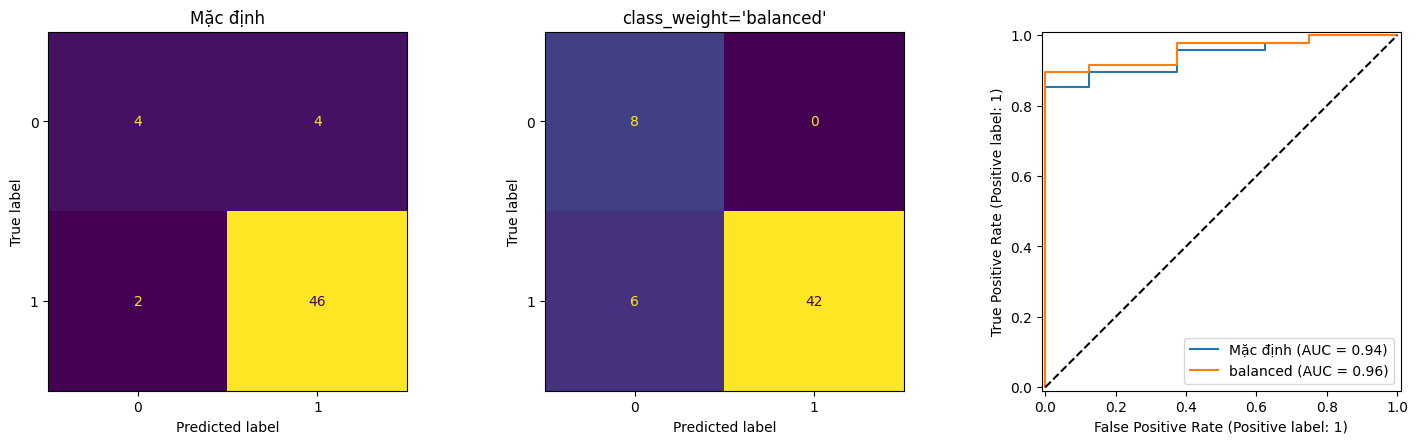

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, colorbar=False, ax=axes[0])
axes[0].set_title('Mặc định')
ConfusionMatrixDisplay.from_estimator(model_cb, X_test, y_test, colorbar=False, ax=axes[1])
axes[1].set_title("class_weight='balanced'")
RocCurveDisplay.from_estimator(model, X_test, y_test, name='Mặc định', ax=axes[2])
RocCurveDisplay.from_estimator(model_cb, X_test, y_test, name='balanced', ax=axes[2])
axes[2].plot([0, 1], [0, 1], 'k--')
plt.tight_layout()
plt.show()

## 4. Chọn ngưỡng phân loại (4.3.4 c)

Nâng ngưỡng làm giảm báo nhầm (FP) nhưng tăng bỏ sót (FN). Với sàng lọc ung thư nên ưu tiên Recall cao.

In [7]:
for tau in [0.5, 0.7, 0.8, 0.9]:
    y_tau = (y_prob >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_tau).ravel()
    print(tau, 'TN=%d FP=%d FN=%d TP=%d' % (tn, fp, fn, tp),
          'Recall=%.3f Đặc hiệu=%.3f' % (tp / (tp + fn), tn / (tn + fp)))

0.5 TN=4 FP=4 FN=2 TP=46 Recall=0.958 Đặc hiệu=0.500
0.7 TN=5 FP=3 FN=3 TP=45 Recall=0.938 Đặc hiệu=0.625
0.8 TN=7 FP=1 FN=6 TP=42 Recall=0.875 Đặc hiệu=0.875
0.9 TN=8 FP=0 FN=8 TP=40 Recall=0.833 Đặc hiệu=1.000


## 5. Kiểm định chéo 5 phần (4.3.4 d)

Tập kiểm tra chỉ có 8 mẫu lớp 0, nên kiểm định chéo cho đánh giá ổn định hơn.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for chi_so in ['accuracy', 'f1', 'roc_auc']:
    diem = cross_val_score(model, X, y, cv=cv, scoring=chi_so)
    print(chi_so, diem.round(3), 'trung bình = %.3f' % diem.mean())

accuracy [0.911 0.909 0.927 0.945 0.891] trung bình = 0.917
f1 [0.947 0.949 0.959 0.969 0.938] trung bình = 0.953
roc_auc [0.948 0.952 0.932 0.973 0.859] trung bình = 0.933
